In [2]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from scipy.stats import norm
from scipy.stats import moyal

In [3]:
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)


def save_plot(filename=None):
    figure = plt.gcf()
    if filename is None:
        title = figure.axes[0].get_title() if figure.axes else "plot"
        filename = re.sub(
            r"[^a-zA-Z0-9_-]+",
            "_",
            title
        ).strip("_").lower()
        filename = filename or "plot"

    figure.savefig(
        PLOTS_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

In [4]:
CSV_PATH = "data_1000e.csv"

COLUMN_NAMES = [
    "RunID",
    "EventID",
    "TrackID",
    "Hit",
    "GlobalTime",
    "TimeSinceZero",
    "TrackLenght",
    "PhotonEnergy",
    "PhotonFlightTime",
    "PhotonCreationTime",
    "Process",
    "NSideReflections"
]

DTYPES = {
    "RunID": "int32",
    "EventID": "int32",
    "trackID": "int32",
    "hit": "category",
    "globaltime": "float64",
    "timesinceelectronhit": "float64",
    "trackLength": "float32",
    "photonEnergy": "float32",
    "photonFlightTime": "float32",
    "photonCreationTime": "float32",
    "creatorProcess": "category",
    "NSideReflections": "int32",
}

data = pd.read_csv(CSV_PATH, comment="#", header=None, names=COLUMN_NAMES, dtype=DTYPES)

counts_data = len(data)
counts_events = data['EventID'].nunique()

print(f"{counts_data:,} Photon-Treffer geladen, {counts_events:,} Events")
data.head()

data["WavelengthNM"] = (1239.841984 / data["PhotonEnergy"])

1,994,560 Photon-Treffer geladen, 1,000 Events


In [19]:
# masks
mask_process_scintillation = data["Process"] == "Scintillation"
mask_process_cerenkov = data["Process"] == "Cerenkov"

mask_hit_top = data["Hit"] == "top"
mask_hit_bottom = data["Hit"] == "bottom"

# all data
data_all = data.copy()

# only Scintillation
data_all_scintillation = data[
    mask_process_scintillation
].copy()

# only Cerenkov
data_all_cerenkov = data[
    mask_process_cerenkov
].copy()

# only top data all
data_all_top = data[
    mask_hit_top
].copy()

# only top data scintillation
data_all_top_scintillation = data[
    (mask_hit_top)
    &
    (mask_process_scintillation)
].copy()

# only top data cerenkov
data_all_top_cerenkov = data[
    (mask_hit_top)
    &
    (mask_process_cerenkov)
].copy()

# only bottom data all
data_all_bottom = data[
    mask_hit_bottom
].copy()

# only bottom data scintillation
data_all_bottom_scintillation = data[
    (mask_hit_bottom)
    &
    (mask_process_scintillation)
].copy()

# only top data cerenkov
data_all_bottom_cerenkov = data[
    (mask_hit_bottom)
    &
    (mask_process_cerenkov)
].copy()

# arrival times
data_arr_times_all = (
    data_all["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_scintillation = (
    data_all_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_cerenkov = (
    data_all_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_top = (
    data_all_top["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_bottom = (
    data_all_bottom["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_top_scintillation = (
    data_all_top_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_top_cerenkov = (
    data_all_top_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_bottom_scintillation = (
    data_all_bottom_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_bottom_cerenkov = (
    data_all_bottom_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_wavelength_all = (
    data_all["WavelengthNM"].dropna().to_numpy()
)

data_wavelength_scintillation = (
    data_all_scintillation["WavelengthNM"].dropna().to_numpy()
)

data_wavelength_cerenkov = (
    data_all_cerenkov["WavelengthNM"].dropna().to_numpy()
)

# creat groups for every event: access via event17 = events[17]
data_events = {
    event_id: event_data.copy()
    for event_id, event_data in data.groupby("EventID")
}

print("Data loaded!")

Data loaded!


In [20]:
def scintillation_pluse_shape(t, A, t0, tau_rise, tau_fall, background):
    t = np.asarray(t, dtype=float)
    dt = t - t0
    shape = np.zeros_like(dt)
    mask = dt > 0
    shape[mask] = (1.0 - np.exp(-dt[mask] / tau_rise)) * np.exp(-dt[mask] / tau_fall)
    return A * shape + background

In [21]:
# Fit-Funktion für einen Datensatz
def fit_dataset(
    times,
    bins=1000,
    fit_range=(0, 10)
):

    counts, bin_edges = np.histogram(
        times,
        bins=bins,
        range=fit_range
    )

    bin_centers = 0.5 * (
        bin_edges[:-1] + bin_edges[1:]
    )

    # Poisson errors
    sigma = np.sqrt(
        np.maximum(counts, 1)
    )

    # amplitude, t0, t_rise, t_fall, background
    initial_values = [
        counts.max(),
        0.1,
        0.350,
        1.600,
        0.0
    ]

    bounds = (
        [
            0.0,       # amplitude
            -1.0,      # t0
            0.001,     # rise
            0.05,      # fall
            0.0        # background
        ],
        [
            np.inf,
            2.0,
            10.0,
            20.0,
            np.inf
        ]
    )

    fit_parameters, covariance = curve_fit(
        scintillation_pluse_shape,
        bin_centers,
        counts,
        p0=initial_values,
        sigma=sigma,
        absolute_sigma=True,
        bounds=bounds,
        maxfev=50000
    )

    errors = np.sqrt(
        np.diag(covariance)
    )

    return (
        counts,
        bin_edges,
        bin_centers,
        fit_parameters,
        errors
    )

In [22]:
def fit_data(times, bins, fit_range = (0,10)):

    (
        counts_single_event,
        edges_single_event,
        centers_single_event,
        params_single_event,
        errors_single_event
    ) = fit_dataset(
        times,
        bins=bins,
        fit_range=fit_range
    )

    return params_single_event, errors_single_event

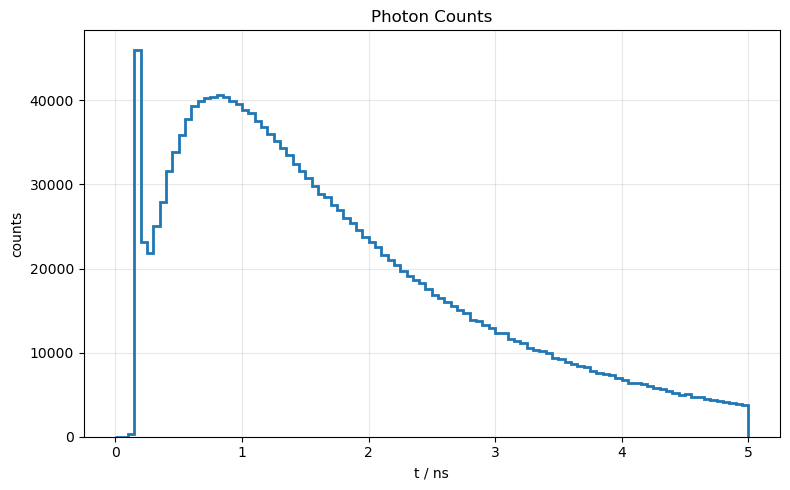

In [23]:
plt.figure(figsize=(8, 5))

plt.hist(
    data_arr_times_all,
    bins=100,
    histtype="step",
    range=(0, 5),
    linewidth=2
)

plt.xlabel("t / ns")
plt.ylabel("counts")
plt.title("Photon Counts")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
data_all_scintillation

,RunID,EventID,TrackID,Hit,GlobalTime,TimeSinceZero,TrackLenght,PhotonEnergy,PhotonFlightTime,PhotonCreationTime,Process,NSideReflections,WavelengthNM
0,0,0,3313,bottom,3.551660,3.224770,38.1120,3.57951,0.143811,3.080960,Scintillation,4,346.371985
1,0,0,3312,bottom,0.572754,0.245865,49.5436,3.43263,0.184424,0.061441,Scintillation,3,361.193016
2,0,0,3310,bottom,3.268410,2.941520,50.9576,3.45716,0.183435,2.758080,Scintillation,8,358.630201
3,0,0,3304,bottom,0.777186,0.450297,48.7501,3.36494,0.171384,0.278913,Scintillation,6,368.458868
4,0,0,3303,bottom,3.631900,3.305010,35.6786,3.56211,0.126462,3.178550,Scintillation,1,348.063924
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1994548,0,999,9090,bottom,5.425950,5.099060,40.5764,3.13212,0.150383,4.948680,Scintillation,5,395.847536
1994549,0,999,9089,bottom,3.278230,2.951340,102.7940,3.38788,0.343163,2.608180,Scintillation,23,365.963961
1994550,0,999,9085,bottom,0.900534,0.573644,48.4775,3.36189,0.164338,0.409307,Scintillation,4,368.793144
1994551,0,999,9081,bottom,0.908162,0.581273,37.0368,3.40390,0.124399,0.456874,Scintillation,3,364.241601


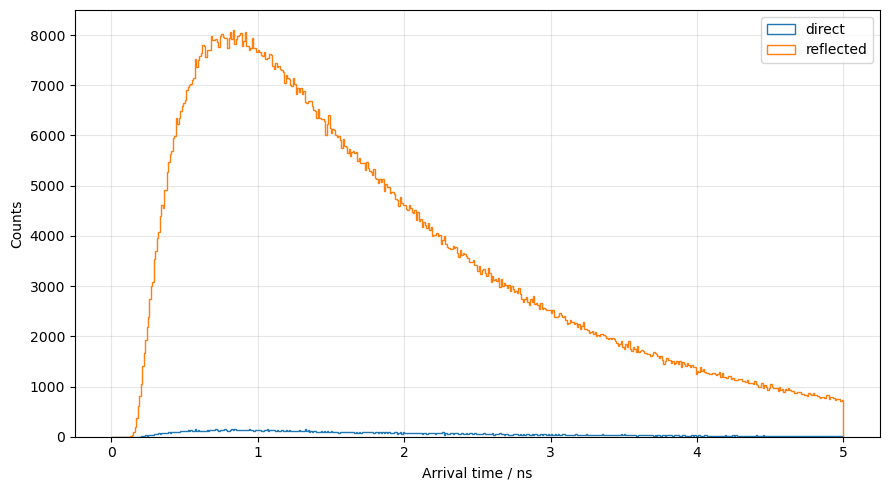

In [49]:
scint = data[
    (data["Process"] == "Scintillation")
].copy()

direct = scint[
    scint["NSideReflections"] == 0
]

reflected = scint[
    scint["NSideReflections"] > 0
]

plt.figure(figsize=(9, 5))

plt.hist(
    direct["TimeSinceZero"],
    bins=500,
    range=(0, 5),
    histtype="step",
    label="direct"
)

plt.hist(
    reflected["TimeSinceZero"],
    bins=500,
    range=(0, 5),
    histtype="step",
    label="reflected"
)

plt.xlabel("Arrival time / ns")
plt.ylabel("Counts")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


direct:
  A            = 241.4771 +- 5.4817
  t0 / ns      = 0.1928 +- 0.0021
  t_rise / ns  = 0.3862 +- 0.0171
  t_fall / ns  = 1.6004 +- 0.0239
  background   = 0.0000 +- 0.2273

reflected:
  A            = 14750.0479 +- 45.0577
  t0 / ns      = 0.1705 +- 0.0003
  t_rise / ns  = 0.4040 +- 0.0024
  t_fall / ns  = 1.5968 +- 0.0029
  background   = 0.4240 +- 0.2751


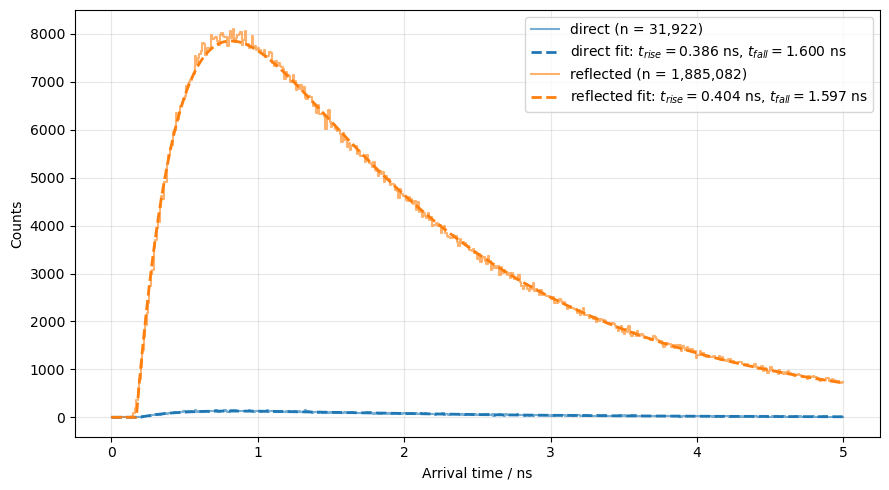

In [50]:
fit_bins = 500
fit_range = (0, 5)

fit_sets = {
    "direct": (direct["TimeSinceZero"].dropna().to_numpy(), "tab:blue"),
    "reflected": (reflected["TimeSinceZero"].dropna().to_numpy(), "tab:orange"),
}

param_names = ["A", "t0 / ns", "t_rise / ns", "t_fall / ns", "background"]

plt.figure(figsize=(9, 5))

for label, (times, color) in fit_sets.items():
    counts, edges, centers, params, errors = fit_dataset(
        times,
        bins=fit_bins,
        fit_range=fit_range
    )

    plt.step(
        centers,
        counts,
        where="mid",
        color=color,
        alpha=0.6,
        label=f"{label} (n = {len(times):,})"
    )

    fit_t = np.linspace(*fit_range, 2000)
    plt.plot(
        fit_t,
        scintillation_pluse_shape(fit_t, *params),
        color=color,
        linestyle="--",
        linewidth=2,
        label=(
            rf"{label} fit: $t_{{rise}}={params[2]:.3f}$ ns, "
            rf"$t_{{fall}}={params[3]:.3f}$ ns"
        )
    )

    print(f"\n{label}:")
    for name, value, error in zip(param_names, params, errors):
        print(f"  {name:12s} = {value:.4f} +- {error:.4f}")

plt.xlabel("Arrival time / ns")
plt.ylabel("Counts")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

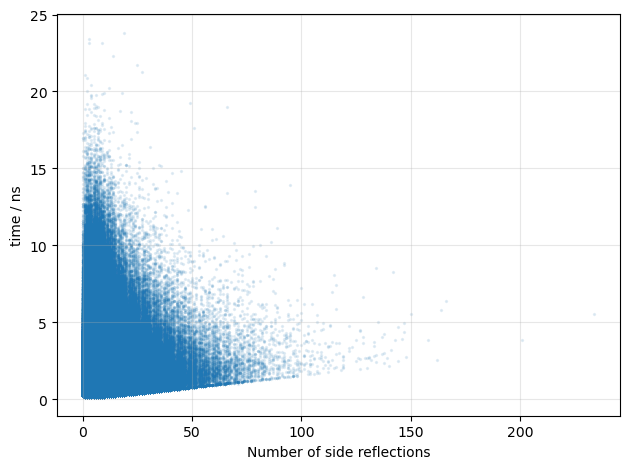

In [42]:
plt.scatter(
    data["NSideReflections"],
    data["TimeSinceZero"],
    s=2,
    alpha=0.1
)

plt.xlabel("Number of side reflections")
plt.ylabel("time / ns")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

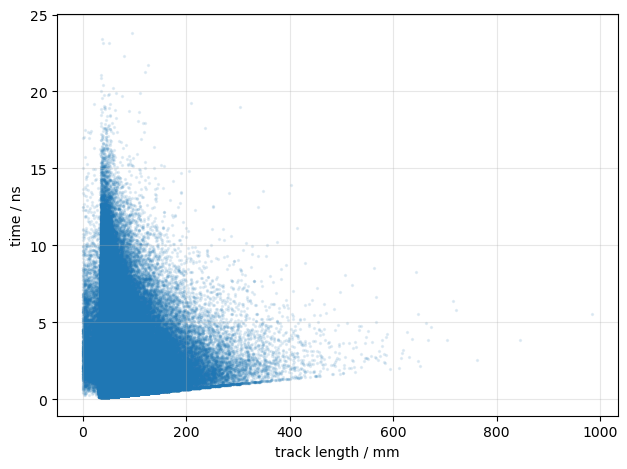

In [40]:
plt.scatter(
    data["TrackLenght"],
    data["TimeSinceZero"],
    s=2,
    alpha=0.1
)

plt.xlabel("track length / mm")
plt.ylabel("time / ns")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()